In [3]:
# Ячейка 1: Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix

# Настройка стилей графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [4]:
# Ячейка 2: Загрузка и базовая очистка
# Загружаем наш идеально очищенный датасет
df = pd.read_csv("../data/processed/nhanes_no_technical.csv")

# Удаляем ID, он не нужен для обучения
df = df.drop(columns=['SEQN'])

# Для классификации возьмем DIQ010 (Диабет: 1=Да, 2=Нет). Перекодируем в 1 и 0.
# Если 1=Да, 2=Нет, то вычитаем 1, чтобы получить 0 и 1
if 'DIQ010' in df.columns:
    df['DIABETES'] = df['DIQ010'].map({1.0: 1, 2.0: 0})
else:
    # Запасной вариант, если колонка называется иначе
    df['DIABETES'] = 0 

# Для регрессии возьмем INDFMPIR (Доход относительно черты бедности)
# Заполним пропуски в целевых переменных медианой для простоты, или удалим строки
df = df.dropna(subset=['INDFMPIR', 'DIABETES'])

print(f"Размер датасета для ML: {df.shape[0]} строк, {df.shape[1]} колонок")

Размер датасета для ML: 76186 строк, 80 колонок


In [5]:
# Ячейка 3: Подготовка признаков (Feature Engineering)
# Выбираем признаки для моделей
features = [
    'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'DMDMARTL',
    'INDFMIN2', 'INDHHIN2', 'ALQ120Q', 'PAQ605', 'MCQ220' # MCQ220 - общее состояние здоровья
]

# Берем только те признаки, которые точно есть в датасете
available_features = [f for f in features if f in df.columns]
print(f"Используемые признаки: {available_features}")

X = df[available_features].copy()
y_reg = df['INDFMPIR']       # Цель для регрессии
y_clf = df['DIABETES']       # Цель для классификации

# Кодирование категориальных переменных (One-Hot Encoding)
X_encoded = pd.get_dummies(X, columns=['RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'DMDMARTL'], drop_first=True)

# Заполнение пропусков в признаках медианой (для чисел) и модой (для категорий после dummy)
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_encoded), columns=X_encoded.columns)

print(f"Итоговая матрица признаков: {X_imputed.shape}")

Используемые признаки: ['RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'DMDMARTL', 'INDFMIN2', 'INDHHIN2', 'ALQ120Q', 'PAQ605', 'MCQ220']
Итоговая матрица признаков: (76186, 25)


In [6]:
# Ячейка 4: Разделение на Train и Test
X_train, X_test, y_reg_train, y_reg_test = train_test_split(X_imputed, y_reg, test_size=0.2, random_state=42)
X_train_clf, X_test_clf, y_clf_train, y_clf_test = train_test_split(X_imputed, y_clf, test_size=0.2, random_state=42)

print(f"Train размер: {X_train.shape[0]}, Test размер: {X_test.shape[0]}")

Train размер: 60948, Test размер: 15238


In [7]:
# Ячейка 5: МОДЕЛЬ 1 - Линейная регрессия (Прогноз уровня дохода INDFMPIR)
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_reg_train)
y_reg_pred = lin_reg.predict(X_test)

print("=== 1. ЛИНЕЙНАЯ РЕГРЕССИЯ (Прогноз INDFMPIR) ===")
print(f"R² (Коэффициент детерминации): {r2_score(y_reg_test, y_reg_pred):.4f}")
print(f"MSE (Среднеквадратичная ошибка): {mean_squared_error(y_reg_test, y_reg_pred):.4f}")

=== 1. ЛИНЕЙНАЯ РЕГРЕССИЯ (Прогноз INDFMPIR) ===
R² (Коэффициент детерминации): 0.7877
MSE (Среднеквадратичная ошибка): 0.5780


In [8]:
# Ячейка 6: МОДЕЛЬ 2 - Нелинейная регрессия (Полиномиальная)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Масштабируем для полиномиальной регрессии, чтобы не было взрыва чисел
scaler = StandardScaler()
X_train_poly_scaled = scaler.fit_transform(X_train_poly)
X_test_poly_scaled = scaler.transform(X_test_poly)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly_scaled, y_reg_train)
y_poly_pred = poly_reg.predict(X_test_poly_scaled)

print("=== 2. НЕЛИНЕЙНАЯ РЕГРЕССИЯ (Polynomial Degree 2) ===")
print(f"R²: {r2_score(y_reg_test, y_poly_pred):.4f}")
print(f"MSE: {mean_squared_error(y_reg_test, y_poly_pred):.4f}")
print("(Сравните R² с линейной: если он выше, значит нелинейные связи есть!)")

=== 2. НЕЛИНЕЙНАЯ РЕГРЕССИЯ (Polynomial Degree 2) ===
R²: 0.8056
MSE: 0.5293
(Сравните R² с линейной: если он выше, значит нелинейные связи есть!)


In [9]:
# Ячейка 7: МОДЕЛЬ 3 - Логистическая регрессия (Прогноз диабета)
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_clf, y_clf_train)
y_clf_pred = log_reg.predict(X_test_clf)

print("=== 3. ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ (Прогноз диабета DIQ010) ===")
print(f"Accuracy (Точность): {accuracy_score(y_clf_test, y_clf_pred):.4f}")
print("\nОтчет по классам:")
print(classification_report(y_clf_test, y_clf_pred, target_names=['Нет диабета (0)', 'Диабет (1)']))

=== 3. ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ (Прогноз диабета DIQ010) ===
Accuracy (Точность): 0.9239

Отчет по классам:
                 precision    recall  f1-score   support

Нет диабета (0)       0.92      1.00      0.96     14076
     Диабет (1)       0.67      0.00      0.01      1162

       accuracy                           0.92     15238
      macro avg       0.80      0.50      0.48     15238
   weighted avg       0.90      0.92      0.89     15238



=== 4. ДЕРЕВО РЕШЕНИЙ (Прогноз диабета) ===
Accuracy: 0.9237


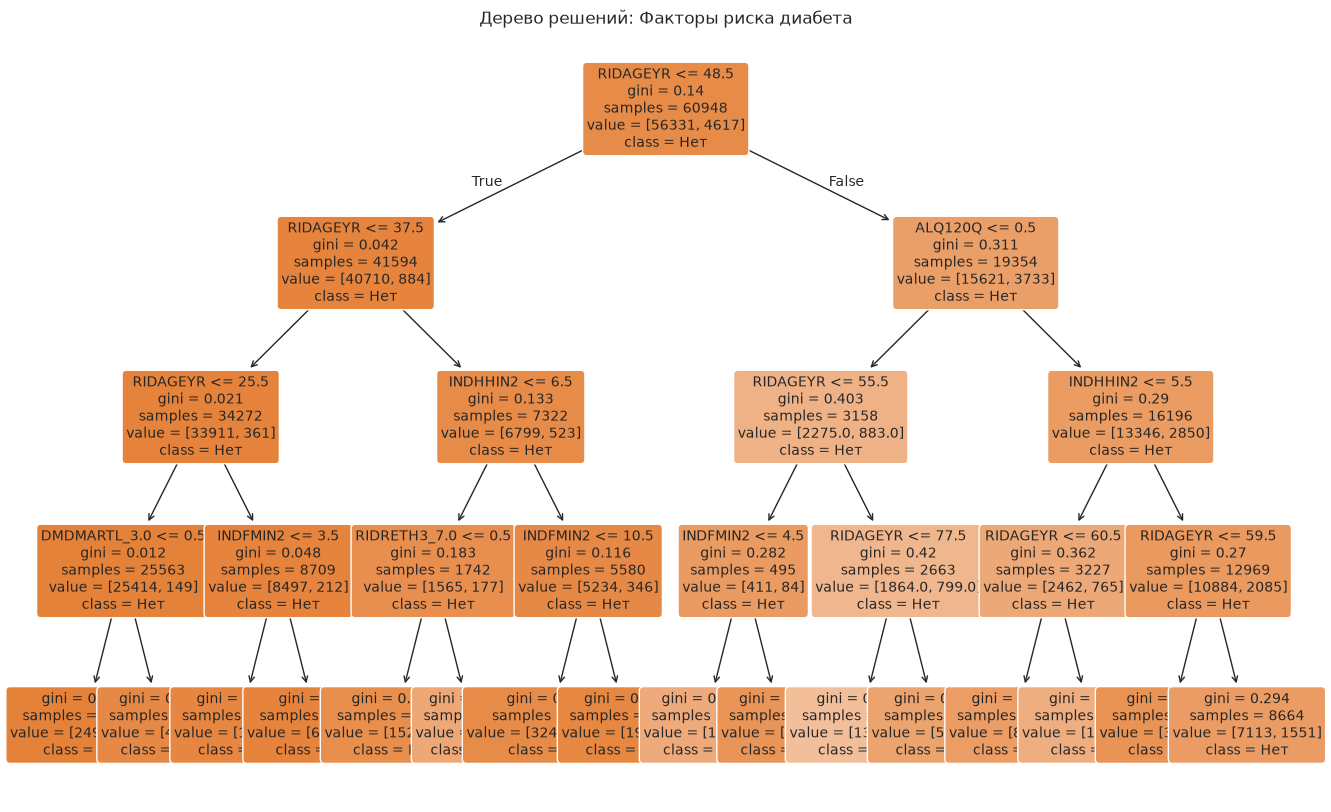

In [10]:
# Ячейка 8: МОДЕЛЬ 4 - Дерево решений (Интерпретируемые правила)
tree_clf = DecisionTreeClassifier(max_depth=4, random_state=42, min_samples_split=20)
tree_clf.fit(X_train_clf, y_clf_train)
y_tree_pred = tree_clf.predict(X_test_clf)

print("=== 4. ДЕРЕВО РЕШЕНИЙ (Прогноз диабета) ===")
print(f"Accuracy: {accuracy_score(y_clf_test, y_tree_pred):.4f}")

# Визуализация дерева
plt.figure(figsize=(16, 10))
plot_tree(tree_clf, 
          feature_names=X_imputed.columns, 
          class_names=['Нет', 'Да'], 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title("Дерево решений: Факторы риска диабета")
plt.show()

Топ-5 самых важных признаков для предсказания:
     Признак  Важность
    RIDAGEYR  0.896993
     ALQ120Q  0.057819
    INDHHIN2  0.034879
    INDFMIN2  0.005564
DMDMARTL_3.0  0.003019


/tmp/ipykernel_17117/2903129195.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Важность', y='Признак', data=feat_imp_df.head(10), palette='viridis')


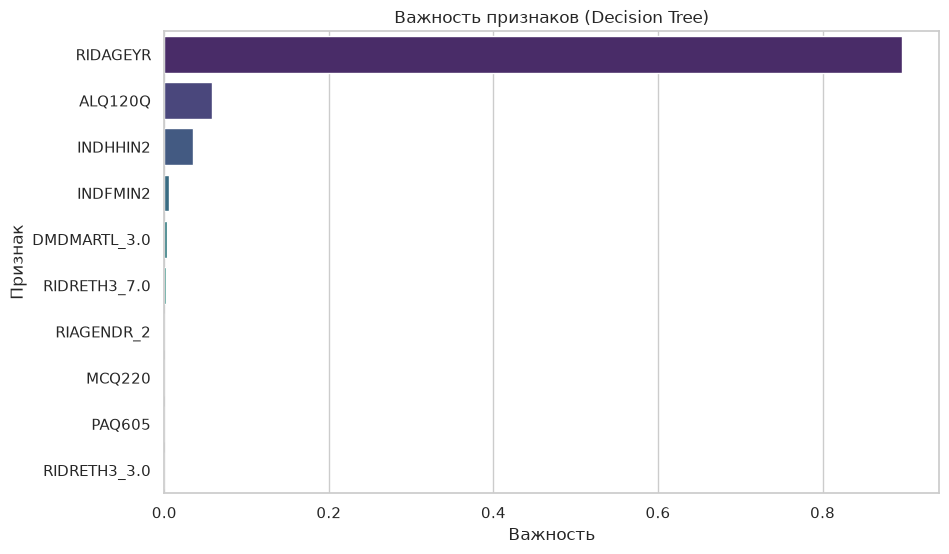

In [11]:
# Ячейка 9: Важность признаков (для DataLens и выводов)
# Берем важность из дерева решений, так как она наиболее интерпретируема
importances = tree_clf.feature_importances_
feature_names = X_imputed.columns
feat_imp_df = pd.DataFrame({'Признак': feature_names, 'Важность': importances})
feat_imp_df = feat_imp_df.sort_values(by='Важность', ascending=False)

print("Топ-5 самых важных признаков для предсказания:")
print(feat_imp_df.head(5).to_string(index=False))

# График важности признаков
plt.figure(figsize=(10, 6))
sns.barplot(x='Важность', y='Признак', data=feat_imp_df.head(10), palette='viridis')
plt.title('Важность признаков (Decision Tree)')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.show()